# Material de aula - FACENS - Aprendizado de Máquina

# <center> RESOLUÇÃO DA ATIVIDADE </center>


## ADALINE e Regra Delta - Laboratório 03

In [17]:
#CÉLULA ADALINE-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [18]:
#CÉLULA ADALINE-LIB-02
#Função para carregamento de dados de treinamento
def loadDataFile(filename) :
    '''
    Esta função faz o carregamento de dados de um arquivo separado por virgulas (csv)
    
    Parametros
    -----------
    filename -> nome do arquivo de dados em formato csv
    
    
    Retorno
    -----------  
    dataframe contendo os dados do arquivo formatados numericamente.
    '''    
    dfFile = pd.read_csv(filename, sep=';', decimal=',', thousands='.')
    
    return dfFile

In [19]:
#CÉLULA ADALINE-LIB-03
# Função para cálculo de normalização de uma amostra
def tales(x1, x1_min, x1_max, x2_min, x2_max) :
    '''
    Esta função faz o escalamento de 1 amostra x1, que pertence ao intervalo [x1_min, x1_max], 
    dentro do intervalo [x2_min, x2_max]
    
    Parametros
    -----------
    x1     -> valor a ser normalizado
    x1_min -> valor minimo atingido por x1
    x1_max -> valor maximo atingido por x1
    x2_min -> valor minimo da escala de destino
    x2_max -> valor maximo da escala de destino    
    
    Retorno
    -----------  
    valor de x1, que pertence ao intervalo [x1_min, x1_max], projetado dentro do intervalo [x2_min, x2_max]
    '''
   
    #Teorema de Tales
    # ( x2 - x2_min ) / ( x2_max - x2_min ) = ( x1 - x1_min ) / (x1_max - % x1_min);
    
    #Definindo x1 como a escala do vetor dado e x2 como a escala de saída (variavel de interesse), isola-se x2:
    x2 = ( ( x1 - x1_min ) / (x1_max - x1_min) )* ( x2_max - x2_min ) + x2_min
    
    return x2

In [20]:
#CÉLULA ADALINE-LIB-04
def scale(x2_min, x2_max, sampleArray) :
    '''
    Esta função faz o escalamento de 1 vetor de amostras para dentro do intervalo [x2_min, x2_max]
    Ela retorna um vetor com os dados normalizados dentro do dominio dado
    
    Parametros
    -----------
    x2_min      -> valor minimo da escala de destino
    x2_max      -> valor maximo da escala de destino
    sampleArray -> vetor a ser normalizado   
    
    Retorno
    -----------  
    vetor sampleArray projetado dentro do intervalo [x2_min, x2_max]   
    '''    
    x_max = max(sampleArray)
    x_min = min(sampleArray)
    
    sampleArrayNorm = [tales(x, x_min, x_max, x2_min, x2_max) for x in sampleArray]
    
    return sampleArrayNorm

In [21]:
#Carregando dataset de treino
dfTrainingFile = loadDataFile('Lab01_training_2.csv')
dfTrainingFile

,Amostra,x1,x2,x3,x4,d
0,1,0.4329,-1.3719,0.7022,-0.8535,1
1,2,0.3024,0.2286,0.8630,2.7909,-1
2,3,0.1349,-0.6445,1.0530,0.5687,-1
3,4,0.3374,-1.7163,0.3670,-0.6283,-1
4,5,1.1434,-0.0485,0.6637,1.2606,1
5,6,1.3749,-0.5071,0.4464,1.3009,1
6,7,0.7221,-0.7587,0.7681,-0.5592,1
7,8,0.4403,-0.8072,0.5154,-0.3129,1
8,9,-0.5231,0.3548,0.2538,1.5776,-1
9,10,0.3255,-2.0000,0.7112,-1.1209,1


In [22]:
#Normalizando dados de treino
dfTrainingFileNorm = dfTrainingFile.copy()
dfTrainingFileNorm['x1'] = scale(-1,1, dfTrainingFile['x1'])
dfTrainingFileNorm['x2'] = scale(-1,1, dfTrainingFile['x2'])
dfTrainingFileNorm['x3'] = scale(-1,1, dfTrainingFile['x3'])

dfTrainingFileNorm

,Amostra,x1,x2,x3,x4,d
0,1,-0.019839,-0.308281,0.452773,-0.8535,1
1,2,-0.153637,0.286612,0.703611,2.7909,-1
2,3,-0.325370,-0.037913,1.000000,0.5687,-1
3,4,-0.117753,-0.436292,-0.070119,-0.6283,-1
4,5,0.708617,0.183616,0.392715,1.2606,1
5,6,0.945968,0.013158,0.053740,1.3009,1
6,7,0.276670,-0.080360,0.555573,-0.5592,1
7,8,-0.012252,-0.098387,0.161376,-0.3129,1
8,9,-1.000000,0.333519,-0.246705,1.5776,-1
9,10,-0.129953,-0.541741,0.466812,-1.1209,1


In [23]:
#Carregando dataset de teste
dfTestFile = loadDataFile('Lab01_operation_2.csv')
dfTestFile

,Amostra,x1,x2,x3,x4
0,1,0.9694,0.6909,0.4334,3.4965
1,2,0.5427,1.3832,0.6390,4.0352
2,3,0.6081,-0.9196,0.5925,0.1016
3,4,-0.1618,0.4694,0.2030,3.0117
4,5,0.1870,-0.2578,0.6124,1.7749
5,6,0.4891,-0.5276,0.4378,0.6439
6,7,0.3777,2.0149,0.7423,3.3932
7,8,1.1498,-0.4067,0.2469,1.5866
8,9,0.9325,1.0950,1.0359,3.3591
9,10,0.5060,1.3317,0.9222,3.7174


In [24]:
#Normalizando dados de teste
dfTestFileNorm = dfTestFile.copy()
dfTestFileNorm['x1'] = scale(-1,1, dfTestFileNorm['x1'])
dfTestFileNorm['x2'] = scale(-1,1, dfTestFileNorm['x2'])
dfTestFileNorm['x3'] = scale(-1,1, dfTestFileNorm['x3'])

dfTestFileNorm

,Amostra,x1,x2,x3,x4
0,1,0.267795,-0.015975,-0.446752,3.4965
1,2,-0.199847,0.231165,0.046944,4.0352
2,3,-0.128171,-0.590897,-0.064714,0.1016
3,4,-0.971944,-0.095047,-1.000000,3.0117
4,5,-0.589676,-0.354645,-0.016929,1.7749
5,6,-0.258590,-0.450959,-0.436187,0.6439
6,7,-0.380678,0.456671,0.294993,3.3932
7,8,0.465505,-0.407800,-0.894585,1.5866
8,9,0.227355,0.128282,1.000000,3.3591
9,10,-0.240068,0.212780,0.726978,3.7174


# 1 - Implementação do algoritmo de treinamento e ajuste de pesos do ADALINE

Utilizando Jupyter e NumPy: para o problema apresentado, construa uma função para o cálculo do ajuste de pesos do ADALINE.

Assinatura: **def adaline_train(eta, epsilon, vInputs, vOutputs, max_epochs) :**

### esta função faz o ajuste dos pesos do ADALINE, com a taxa de aprendizado dada, juntamente com o vetor de amostras e de saídas desejadas dentro do limite de treinamento e margem de erro pre-estabelecidos.
    
**Retorno da Função:** Retorna uma tupla contendo os pesos ajustados e a quantidade de épocas executadas para o treinamento

In [25]:
#CÉLULA ADALINE-LIB-05
def adaline_train(eta, epsilon, vInputs, vOutputs, max_epochs) :
    '''
    Algoritmo de treinamento do ADALINE
    
    Parametros
    -----------
    eta        -> taxa de aprendizado
    epsilon    -> criterio de parada baseado em minimo erro quadratico médio
    inputs     -> vetor/matriz com as entradas
    outputs    -> vetor/matriz com as saidas
    max_epochs -> criterio de parada por epocas de treinamento
    
    Retorno
    -------
    Este método retorna uma tupla contendo o vetor de pesos ajustado, o numero de epocas executadas no treinamento e os valores 
    do Erro Quadrático Médio (MSE) em cada época.
    '''
    
    nInputs  = vInputs.shape[0]
    nSamples = vInputs.shape[1]
        
    #O vetor terá 'nInputs' linhas x 1 coluna
    vWeights = np.random.rand(nInputs, 1)
    
    MSE = [] # MSE: Mean Squred Error    
    for epochCounter in range(max_epochs) :
        
        epoch_error = 0  #valor de erro 
        for k in range(nSamples) :
            #Com esta notação, pegaremos a coluna k no formato de vetor-coluna vInputs[:, [k]]
            #Com esta notação, pegaremos a coluna k no formato de vetorlinha vInputs[:, k]
            x = vInputs[:, [k]]
            d = vOutputs[k]
            
            #Calcula saída do bloco associador do ADALINE
            u = np.matmul(vWeights.T, x)

            #Corrige pesos
            vWeights += eta * (d - u) * x

            #Acumula o erro do bloco associador para uma época de treinamento
            epoch_error += (d - u)**2           
        
        #Calcula o EQM e verifica criterio de parada
        MSE.append( np.asscalar(epoch_error / nSamples))
                
        if( epochCounter > 0 and abs(MSE[epochCounter] - MSE[epochCounter-1]) < epsilon ) :
            break            
    
    return (vWeights, epochCounter+1, MSE)

# 2 - Implementação do algoritmo de operação do ADALINE

Utilizando Jupyter e NumPy: para o problema apresentado, construa uma função para o cálculo de saída do perceptron.

Assinatura: **def adaline_operation(vWeights, vInputs) :**

### esta função faz o cálculo do valor de saída do utilizando valores de pesos para um ADALINE pré-ajustado.
    
**Retorno da Função:** Retorna um escalar com o valor de saída, no caso -1 ou 1

In [26]:
#CÉLULA ADALINE-LIB-06
def adaline_operation(vWeights, vInputs) :
    '''Algoritmo de operação do ADALINE Simples
    
    Parametros
    -----------
    vWeights : vetor/matriz com os pesos
    inputs   : vetor/matriz com as entradas
    
    Retorno
    -------
    Este método retorna o valor de saída do ADALINE calculado segundo sua função de ativação signal(.)   
    ''' 

    x = vInputs

    #Calcula saída do ADALINE
    u = np.matmul(vWeights.T, x)
    y = np.sign(u)
    
    return np.asscalar(y) #converte o numpy array 1x1 em um unico valor escalar.

# 3 - Implementação do algoritmo de execução do treinamento e operação do ADALINE

### Um sistema de gerenciamento automático de controle de duas válvulas, situado a 500 metros de um processo industrial, envia um sinal codificado constituído de quatro grandezas {x1, x2, x3 e x4} que são necessárias para o ajuste de cada uma das válvulas. 

### Conforme mostra a figura abaixo, a mesma via de comunicação é utilizada para acionamento de ambas as válvulas, sendo que o comutador localizado próximo das válvulas deve decidir se o sinal é para a válvula A ou B.

![image.png](attachment:image.png)

### Entretanto, durante a transmissão, os sinais sofrem interferências que alteram o conteúdo das informações transmitidas. Para resolver este problema, a equipe de engenheiros e cientistas pretende treinar uma rede ADALINE para classificar os sinais ruidosos, confirmando ao sistema comutador se os dados devem ser encaminhados para o comando de ajuste da válvula A ou B. 

### Assim, baseado nas medições dos sinais já com ruídos, formou-se um conjunto de treinamento, tomando por convenção o valor –1 para os sinais que devem ser encaminhados para o ajuste da válvula A e o valor +1 se os mesmos devem ser enviados para a válvula B. Assim, a estrutura do ADALINE é mostrada na figura abaixo:


![image.png](attachment:image.png)

### Utilize o algoritmo de treinamento da Regra Delta para classificação de padrões no ADALINE, com os seguintes parâmetros: 

### 1. Taxa de aprendizado $ \eta = 0,0025 $
### 2. Precisão $ \epsilon = 10^{-6} $

### Realize as seguintes atividades:

## 3.1 - Implemente o código que realiza o treinamento do ADALINE para o problema dado.

## ADALINE - inicio

In [28]:
#CÉLULA ADALINE-MAIN-01

#Parâmetros
eta = 0.0025
epsilon = 10**(-6)
nInputs = 4
max_epochs = 10000

#Carrega dados - Treino
dfTrainingFile = loadDataFile('Lab01_training_2.csv')
dfTrainingFileNorm = dfTrainingFile.copy()

#Normaliza dados - Treino
dfTrainingFileNorm['x1'] = scale(-1,1, dfTrainingFile['x1'])
dfTrainingFileNorm['x2'] = scale(-1,1, dfTrainingFile['x2'])
dfTrainingFileNorm['x3'] = scale(-1,1, dfTrainingFile['x3'])
dfTrainingFileNorm['x4'] = scale(-1,1, dfTrainingFile['x4'])

nSamples = len (dfTrainingFileNorm['x1'])

#Monta vetor de entradas e adiciona a coluna '-1' (bias)
col0 = np.ones((nSamples, 1)) * (-1)
col1 = dfTrainingFileNorm['x1'].values.reshape(nSamples, 1)
col2 = dfTrainingFileNorm['x2'].values.reshape(nSamples, 1)
col3 = dfTrainingFileNorm['x3'].values.reshape(nSamples, 1)
col4 = dfTrainingFileNorm['x4'].values.reshape(nSamples, 1)

vInputs = np.array(col0)
vInputs = np.append(vInputs, col1, axis=1) #axis = 1 -> coluna
vInputs = np.append(vInputs, col2, axis=1) #axis = 1 -> coluna
vInputs = np.append(vInputs, col3, axis=1) #axis = 1 -> coluna
vInputs = np.append(vInputs, col4, axis=1) #axis = 1 -> coluna
# print(vInputs.T)

#Vetor de saídas do treinamento
vOutputs = dfTrainingFileNorm['d'].values.reshape(nSamples, 1)
# print(vOutputs.shape)

#Executa o treinamento
(vWeights, nEpochs, MSE) = adaline_train(eta, epsilon, vInputs.T, vOutputs, max_epochs)

print(nEpochs)
print(vWeights)
print(len(MSE))

3119
[[ 0.64333944]
 [ 1.26192316]
 [ 4.34023361]
 [-0.28783965]
 [-4.83096423]]
3119


## 3.2 - Implemente o código que valida o resultado do treinamento

In [29]:
#Verifica resultados 
vY=[]
for k in range(nSamples):
    y = adaline_operation(vWeights, vInputs[[k], :].T)
    vY.append(y)

dfValidation = dfTrainingFile.copy()
dfValidation['y'] = vY

results = dfValidation['y'] == dfValidation['d']
accuracy = sum(results) / len(results) * 100

print('Taxa de acerto do conjunto de treinamento: {}%'.format(accuracy))

Taxa de acerto do conjunto de treinamento: 91.42857142857143%


## 3.3 - Implemente o código que executa o ADALINE treinado com dados de operação

In [31]:
#Carrega dados - Teste
dfTestFile = loadDataFile('Lab01_operation_2.csv')
dfTestFileNorm = dfTestFile.copy()

#Normaliza dados - Teste
dfTestFileNorm['x1'] = scale(-1,1, dfTestFileNorm['x1'])
dfTestFileNorm['x2'] = scale(-1,1, dfTestFileNorm['x2'])
dfTestFileNorm['x3'] = scale(-1,1, dfTestFileNorm['x3'])
dfTestFileNorm['x4'] = scale(-1,1, dfTestFileNorm['x4'])

nSamples = len (dfTestFileNorm['x1'])

#Monta vetor de entradas e adiciona a coluna '-1' (bias)
col0 = np.ones((nSamples, 1)) * (-1)
col1 = dfTestFileNorm['x1'].values.reshape(nSamples, 1)
col2 = dfTestFileNorm['x2'].values.reshape(nSamples, 1)
col3 = dfTestFileNorm['x3'].values.reshape(nSamples, 1)
col4 = dfTestFileNorm['x4'].values.reshape(nSamples, 1)

vTestInputs = np.array(col0)
vTestInputs = np.append(vTestInputs, col1, axis=1) #axis = 1 -> coluna
vTestInputs = np.append(vTestInputs, col2, axis=1) #axis = 1 -> coluna
vTestInputs = np.append(vTestInputs, col3, axis=1) #axis = 1 -> coluna
vTestInputs = np.append(vTestInputs, col4, axis=1) #axis = 1 -> coluna

vY=[]
for k in range(nSamples):
    y = adaline_operation(vWeights, vInputs[[k], :].T)
    vY.append(y)

print(vY)

[1.0, -1.0, -1.0, 1.0, 1.0, 1.0, 1.0, 1.0, -1.0, -1.0, 1.0, -1.0, 1.0, 1.0, -1.0]


In [32]:
dfTestFile['y'] = vY

classes = [ 'A' if(x==-1) else 'B' for x in vY]
dfTestFile['classes'] = classes

#Exibe o dataframe com entradas e saidas classificadas
dfTestFile

,Amostra,x1,x2,x3,x4,y,classes
0,1,0.9694,0.6909,0.4334,3.4965,1.0,B
1,2,0.5427,1.3832,0.6390,4.0352,-1.0,A
2,3,0.6081,-0.9196,0.5925,0.1016,-1.0,A
3,4,-0.1618,0.4694,0.2030,3.0117,1.0,B
4,5,0.1870,-0.2578,0.6124,1.7749,1.0,B
5,6,0.4891,-0.5276,0.4378,0.6439,1.0,B
6,7,0.3777,2.0149,0.7423,3.3932,1.0,B
7,8,1.1498,-0.4067,0.2469,1.5866,1.0,B
8,9,0.9325,1.0950,1.0359,3.3591,-1.0,A
9,10,0.5060,1.3317,0.9222,3.7174,-1.0,A


## 3.4 - Implemente o código que exibe o gráfico da evolução do EQM ao longo das épocas de treinamento

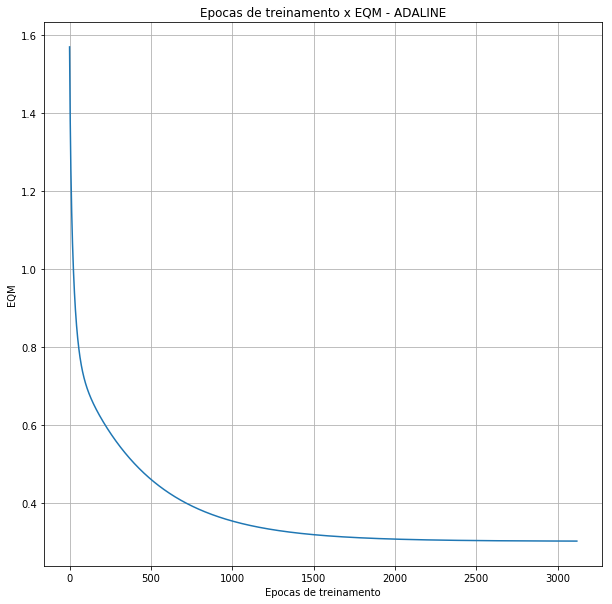

In [33]:
fig = plt.figure(figsize=(10,10))
plt.grid()
plt.xlabel('Epocas de treinamento')
plt.ylabel('EQM')
plt.title('Epocas de treinamento x EQM - ADALINE')
plt.plot(range(nEpochs), MSE)